# In this notebook I Fine-tuned a pretrained YOLO11n model on a custom license-plate detection dataset

This notebook uses 2 different datasets.

First one is : [https://www.kaggle.com/datasets/ronakgohil/license-plate-dataset/data]

and the second one is : [https://www.kaggle.com/datasets/skhalili/iraniancarnumberplate?select=car]

# Step 1 | Installing and Importing libraries

In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.3 MB/s eta 0:00:00


In [2]:
# for yolo
from ultralytics import YOLO

# pytorch
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

import os
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import Image
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
print("CUDA available:", torch.cuda.is_available())
print("Current device:", device)
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA available: True
Current device: cuda
Device name: Tesla T4


# Step 2 | Preprocessing and visualizing images

In [6]:
image_file = os.listdir(train_image_path)[0]
image_path = os.path.join(train_image_path, image_file)
label_path = os.path.join(train_label_path, image_file.replace(".jpg", ".txt"))

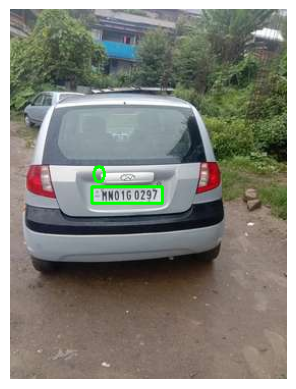

In [7]:
img = cv2.imread(image_path)
h, w, _ = img.shape

with open(label_path, "r") as f:
    for line in f.readlines():
        cls, x_c, y_c, bw, bh = map(float, line.strip().split())

        # YOLO coords → pixel coords
        x_c, y_c, bw, bh = x_c*w, y_c*h, bw*w, bh*h
        x1, y1 = int(x_c - bw/2), int(y_c - bh/2)
        x2, y2 = int(x_c + bw/2), int(y_c + bh/2)

        # drawing bounding box
        cv2.rectangle(img, (x1, y1), (x2, y2), (0,255,0), 2)
        cv2.putText(img, str(int(cls)), (x1, y1-5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

# visualization
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Step 3 | Fine-tuning

In [8]:
# loading the model
model = YOLO("yolo11n.pt")

In [9]:
# path to daya.yaml
data_yaml = "/kaggle/input/datasets/sadafpj/dataset/dataset.yaml"

In [10]:
# training the model
train_results = model.train(data=data_yaml, epochs=20, imgsz=640, device=0)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/sadafpj/dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      2.93G        1.2      1.225      1.101         10        640: 100% ━━━━━━━━━━━━ 169/169 7.6it/s 22.3s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.6it/s 1.2s0.2s
                   all        212        215      0.902      0.897      0.937      0.651

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      2.93G      1.197     0.9763       1.11         16        640: 100% ━━━━━━━━━━━━ 169/169 7.7it/s 22.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.5it/s 1.3s0.2s
                   all        212        215      0.907      0.812      0.896      0.633

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      2.93G      1.156     0.8482      1.091         16        640: 100% ━━━━━━━━━━━━ 169/169 7.7it/s 21.8s0.3ss
                 Class     Images  

## Step 3.1 | Let's save the results and see how was the training!

In [11]:
yolov11n_results_dict = train_results.results_dict
print(yolov11n_results_dict)

{'metrics/precision(B)': 0.9906086701884493, 'metrics/recall(B)': 0.9812211884409802, 'metrics/mAP50(B)': 0.9906100717558785, 'metrics/mAP50-95(B)': 0.8231598332636061, 'fitness': 0.8231598332636061}


### There are 3 types of loss here :

    1. Localization Error
    
    2. Classification Error
    
    3.Confidence/Objectness-related Error

### class ----> 0 = license_plate

In [12]:
result_path = "/kaggle/working/runs/detect/train"

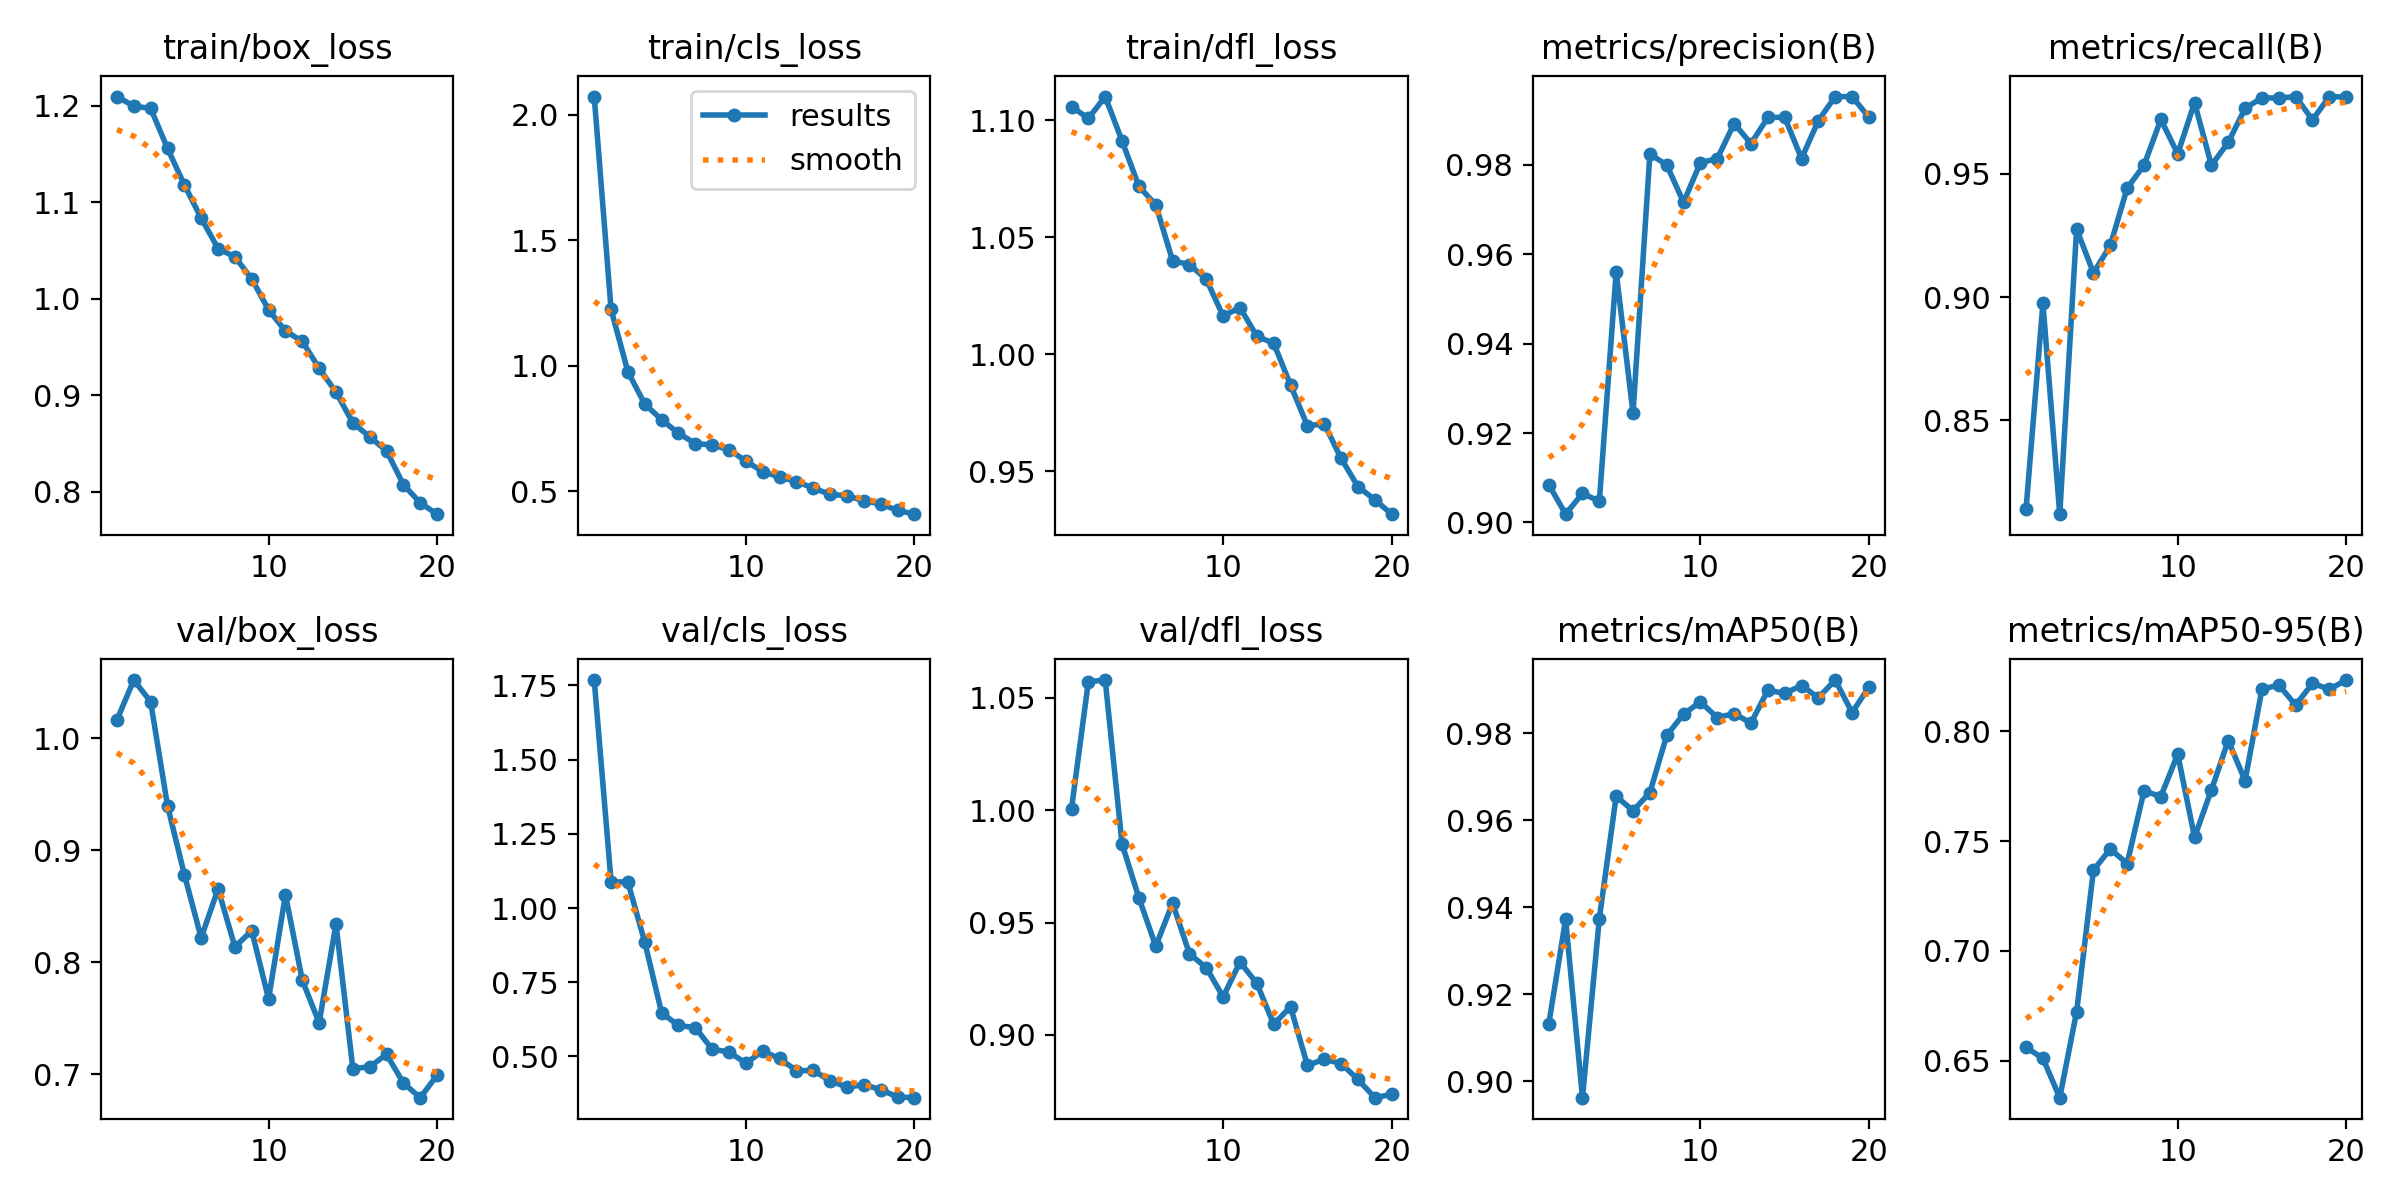

In [13]:
display(Image(f"{result_path}/results.png", width=800, height=800))

In [14]:
df = pd.read_csv(f"{result_path}/results.csv")
display(df)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,59.3172,1.20978,2.07318,1.10581,0.90845,0.81395,0.91313,0.65609,1.01641,1.76808,1.00073,0.000663,0.000663,0.000663
1,2,83.3380,1.19988,1.22494,1.10070,0.90185,0.89747,0.93723,0.65110,1.05197,1.08900,1.05720,0.001264,0.001264,0.001264
2,3,107.1830,1.19741,0.97634,1.11007,0.90651,0.81183,0.89619,0.63319,1.03257,1.08699,1.05793,0.001798,0.001798,0.001798
3,4,130.6790,1.15608,0.84818,1.09113,0.90473,0.92759,0.93738,0.67227,0.93993,0.88483,0.98493,0.001703,0.001703,0.001703
4,5,154.4050,1.11823,0.78571,1.07171,0.95601,0.90980,0.96552,0.73680,0.87826,0.64716,0.96100,0.001604,0.001604,0.001604
5,6,178.4650,1.08362,0.73158,1.06379,0.92445,0.92093,0.96217,0.74642,0.82182,0.60443,0.93948,0.001505,0.001505,0.001505
6,7,201.7040,1.05219,0.69082,1.03992,0.98237,0.94419,0.96634,0.73981,0.86557,0.59714,0.95864,0.001406,0.001406,0.001406
7,8,225.7170,1.04356,0.68494,1.03824,0.97995,0.95349,0.97950,0.77284,0.81384,0.52428,0.93606,0.001307,0.001307,0.001307
8,9,249.9240,1.02069,0.66650,1.03199,0.97158,0.97209,0.98440,0.77032,0.82812,0.51511,0.92990,0.001208,0.001208,0.001208
9,10,273.4700,0.98856,0.62078,1.01627,0.98046,0.95814,0.98721,0.78958,0.76723,0.47717,0.91687,0.001109,0.001109,0.001109


In [15]:
best_epoch = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(best_epoch)

epoch                    20.000000
time                    497.056000
train/box_loss            0.776740
train/cls_loss            0.409340
train/dfl_loss            0.931620
metrics/precision(B)      0.990610
metrics/recall(B)         0.981220
metrics/mAP50(B)          0.990610
metrics/mAP50-95(B)       0.823350
val/box_loss              0.699180
val/cls_loss              0.361210
val/dfl_loss              0.873500
lr/pg0                    0.000119
lr/pg1                    0.000119
lr/pg2                    0.000119
Name: 19, dtype: float64


### RESULTS: 

The model training was good. Loss functions are decreasing for all 3 loss.

Precision and recall are also very well.

Metrics/mAP50(B) is good but metrics/mAP50-95(B) accuracy has decreased. So it is harder for the model to give us precise measurements.

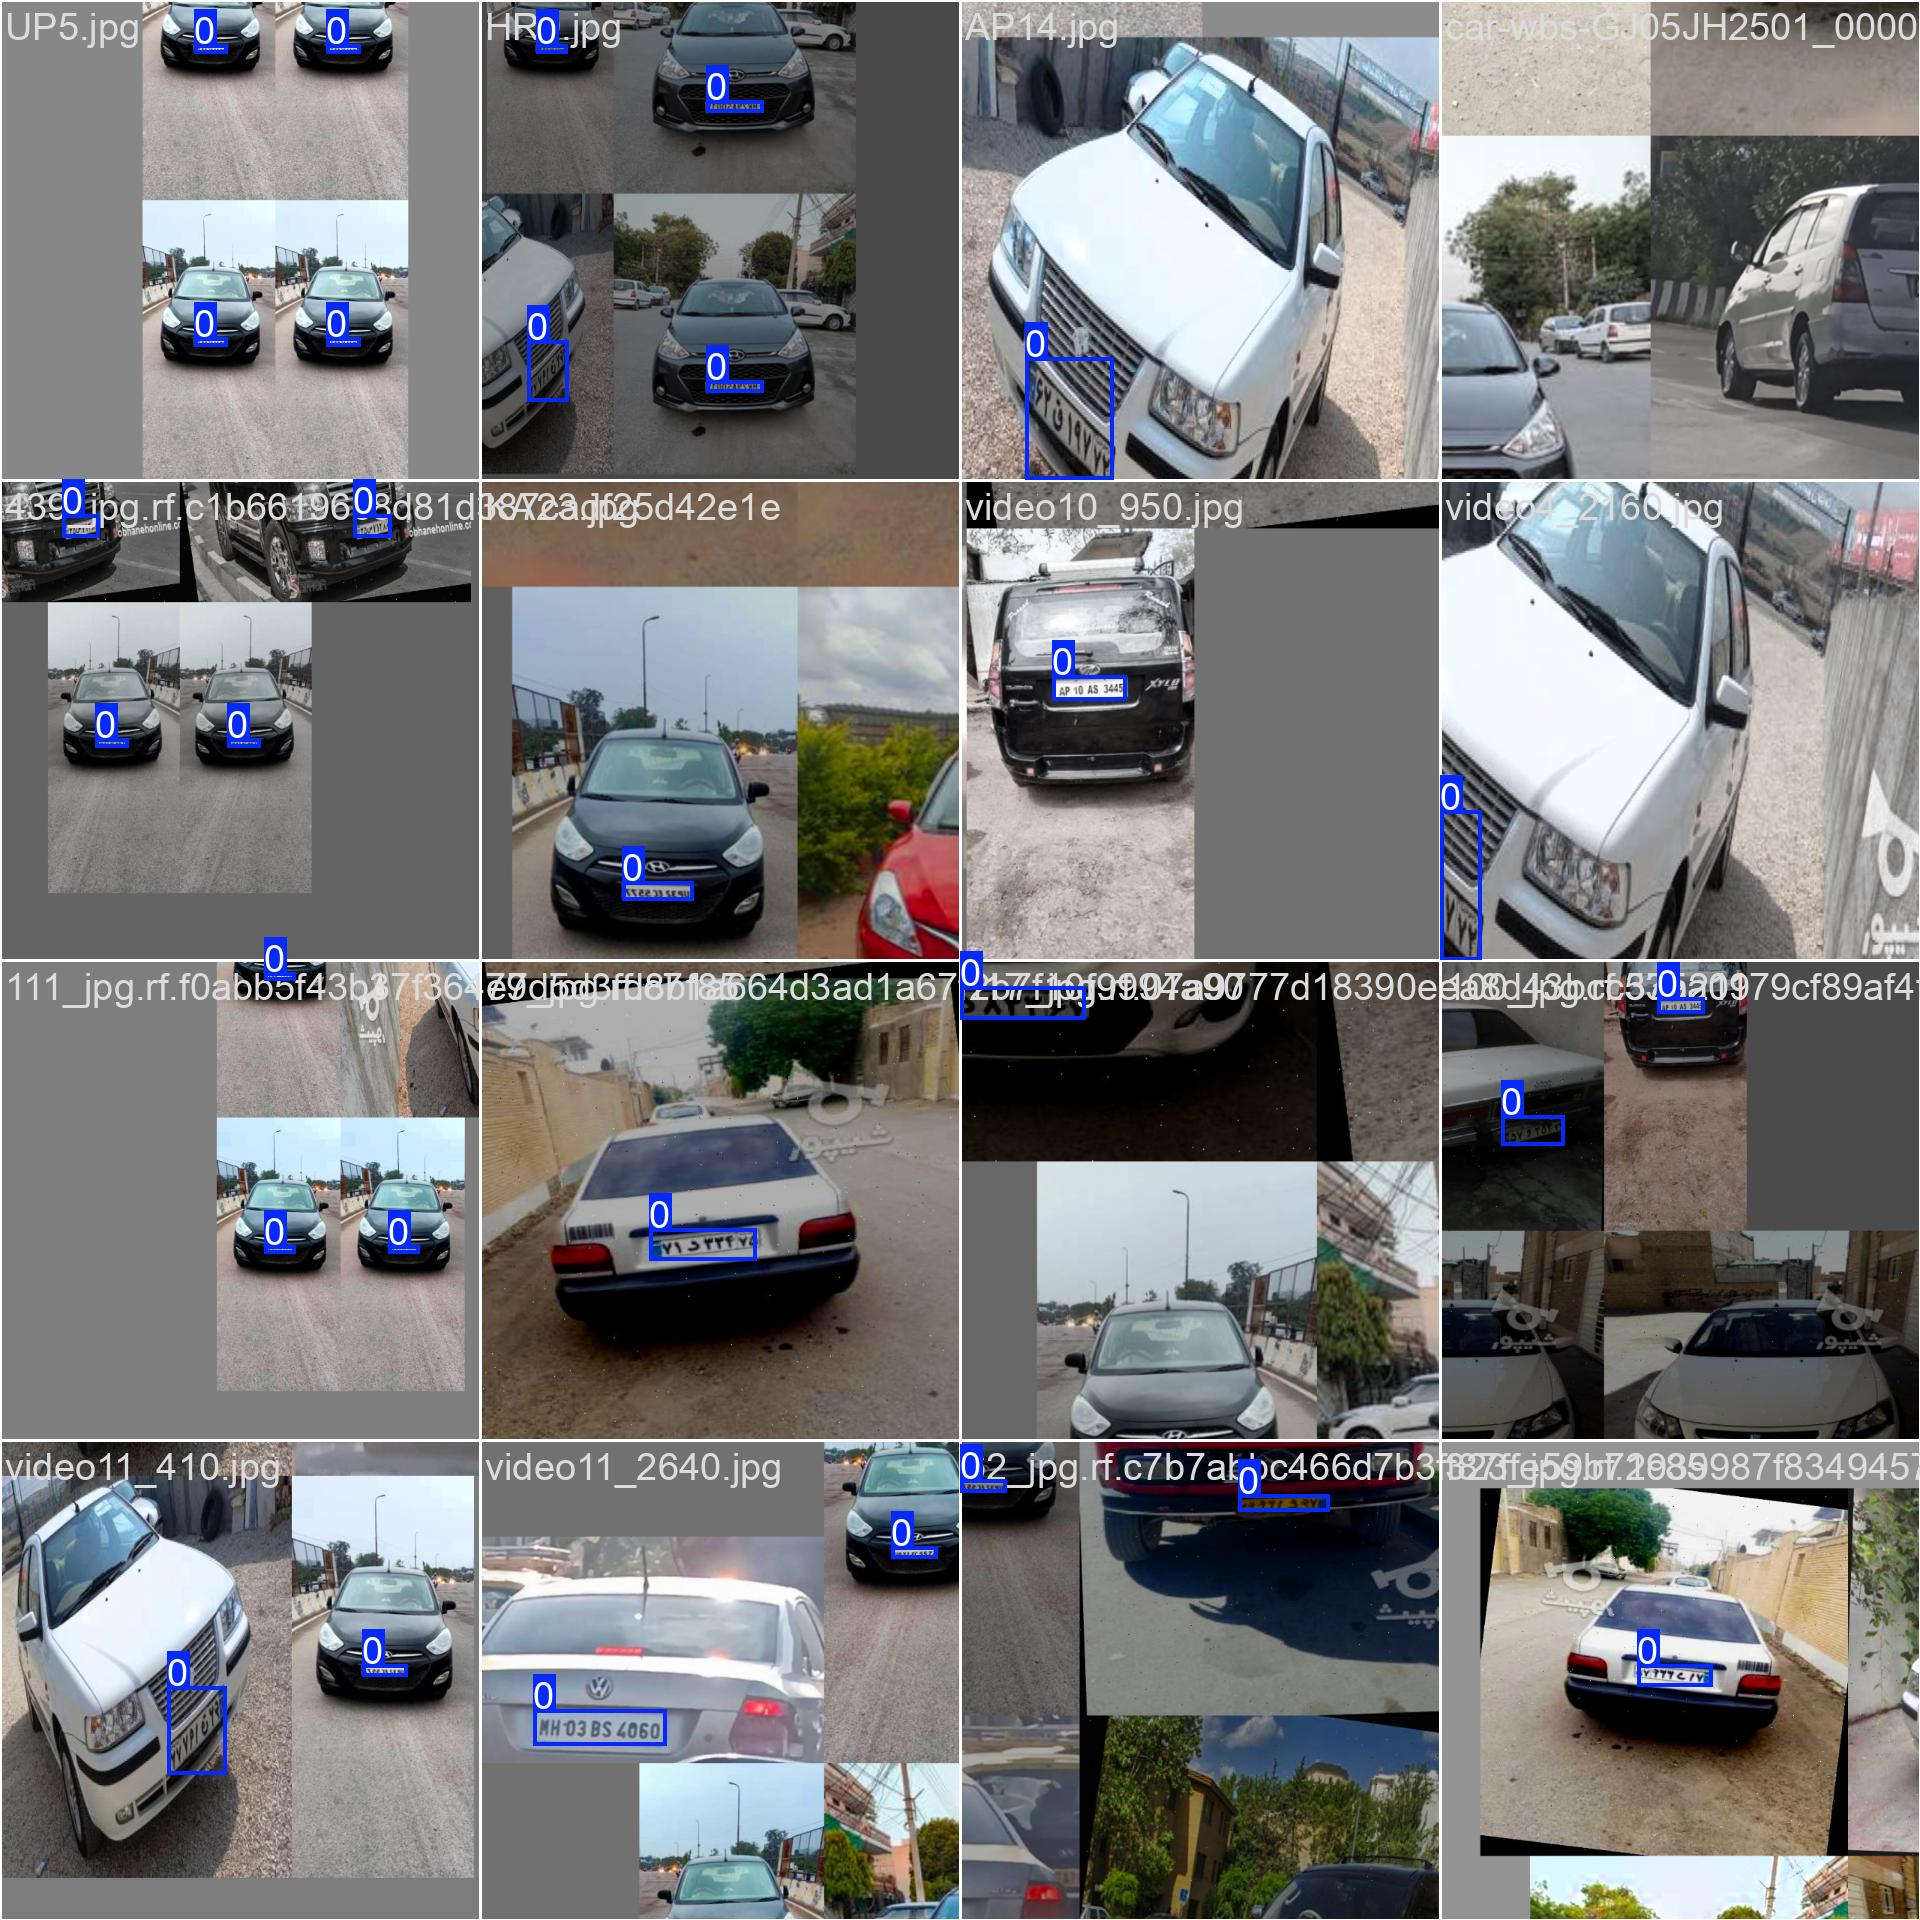

In [23]:
# let's look at the dataset
display(Image(f"{result_path}/train_batch0.jpg", width=600, height=600))

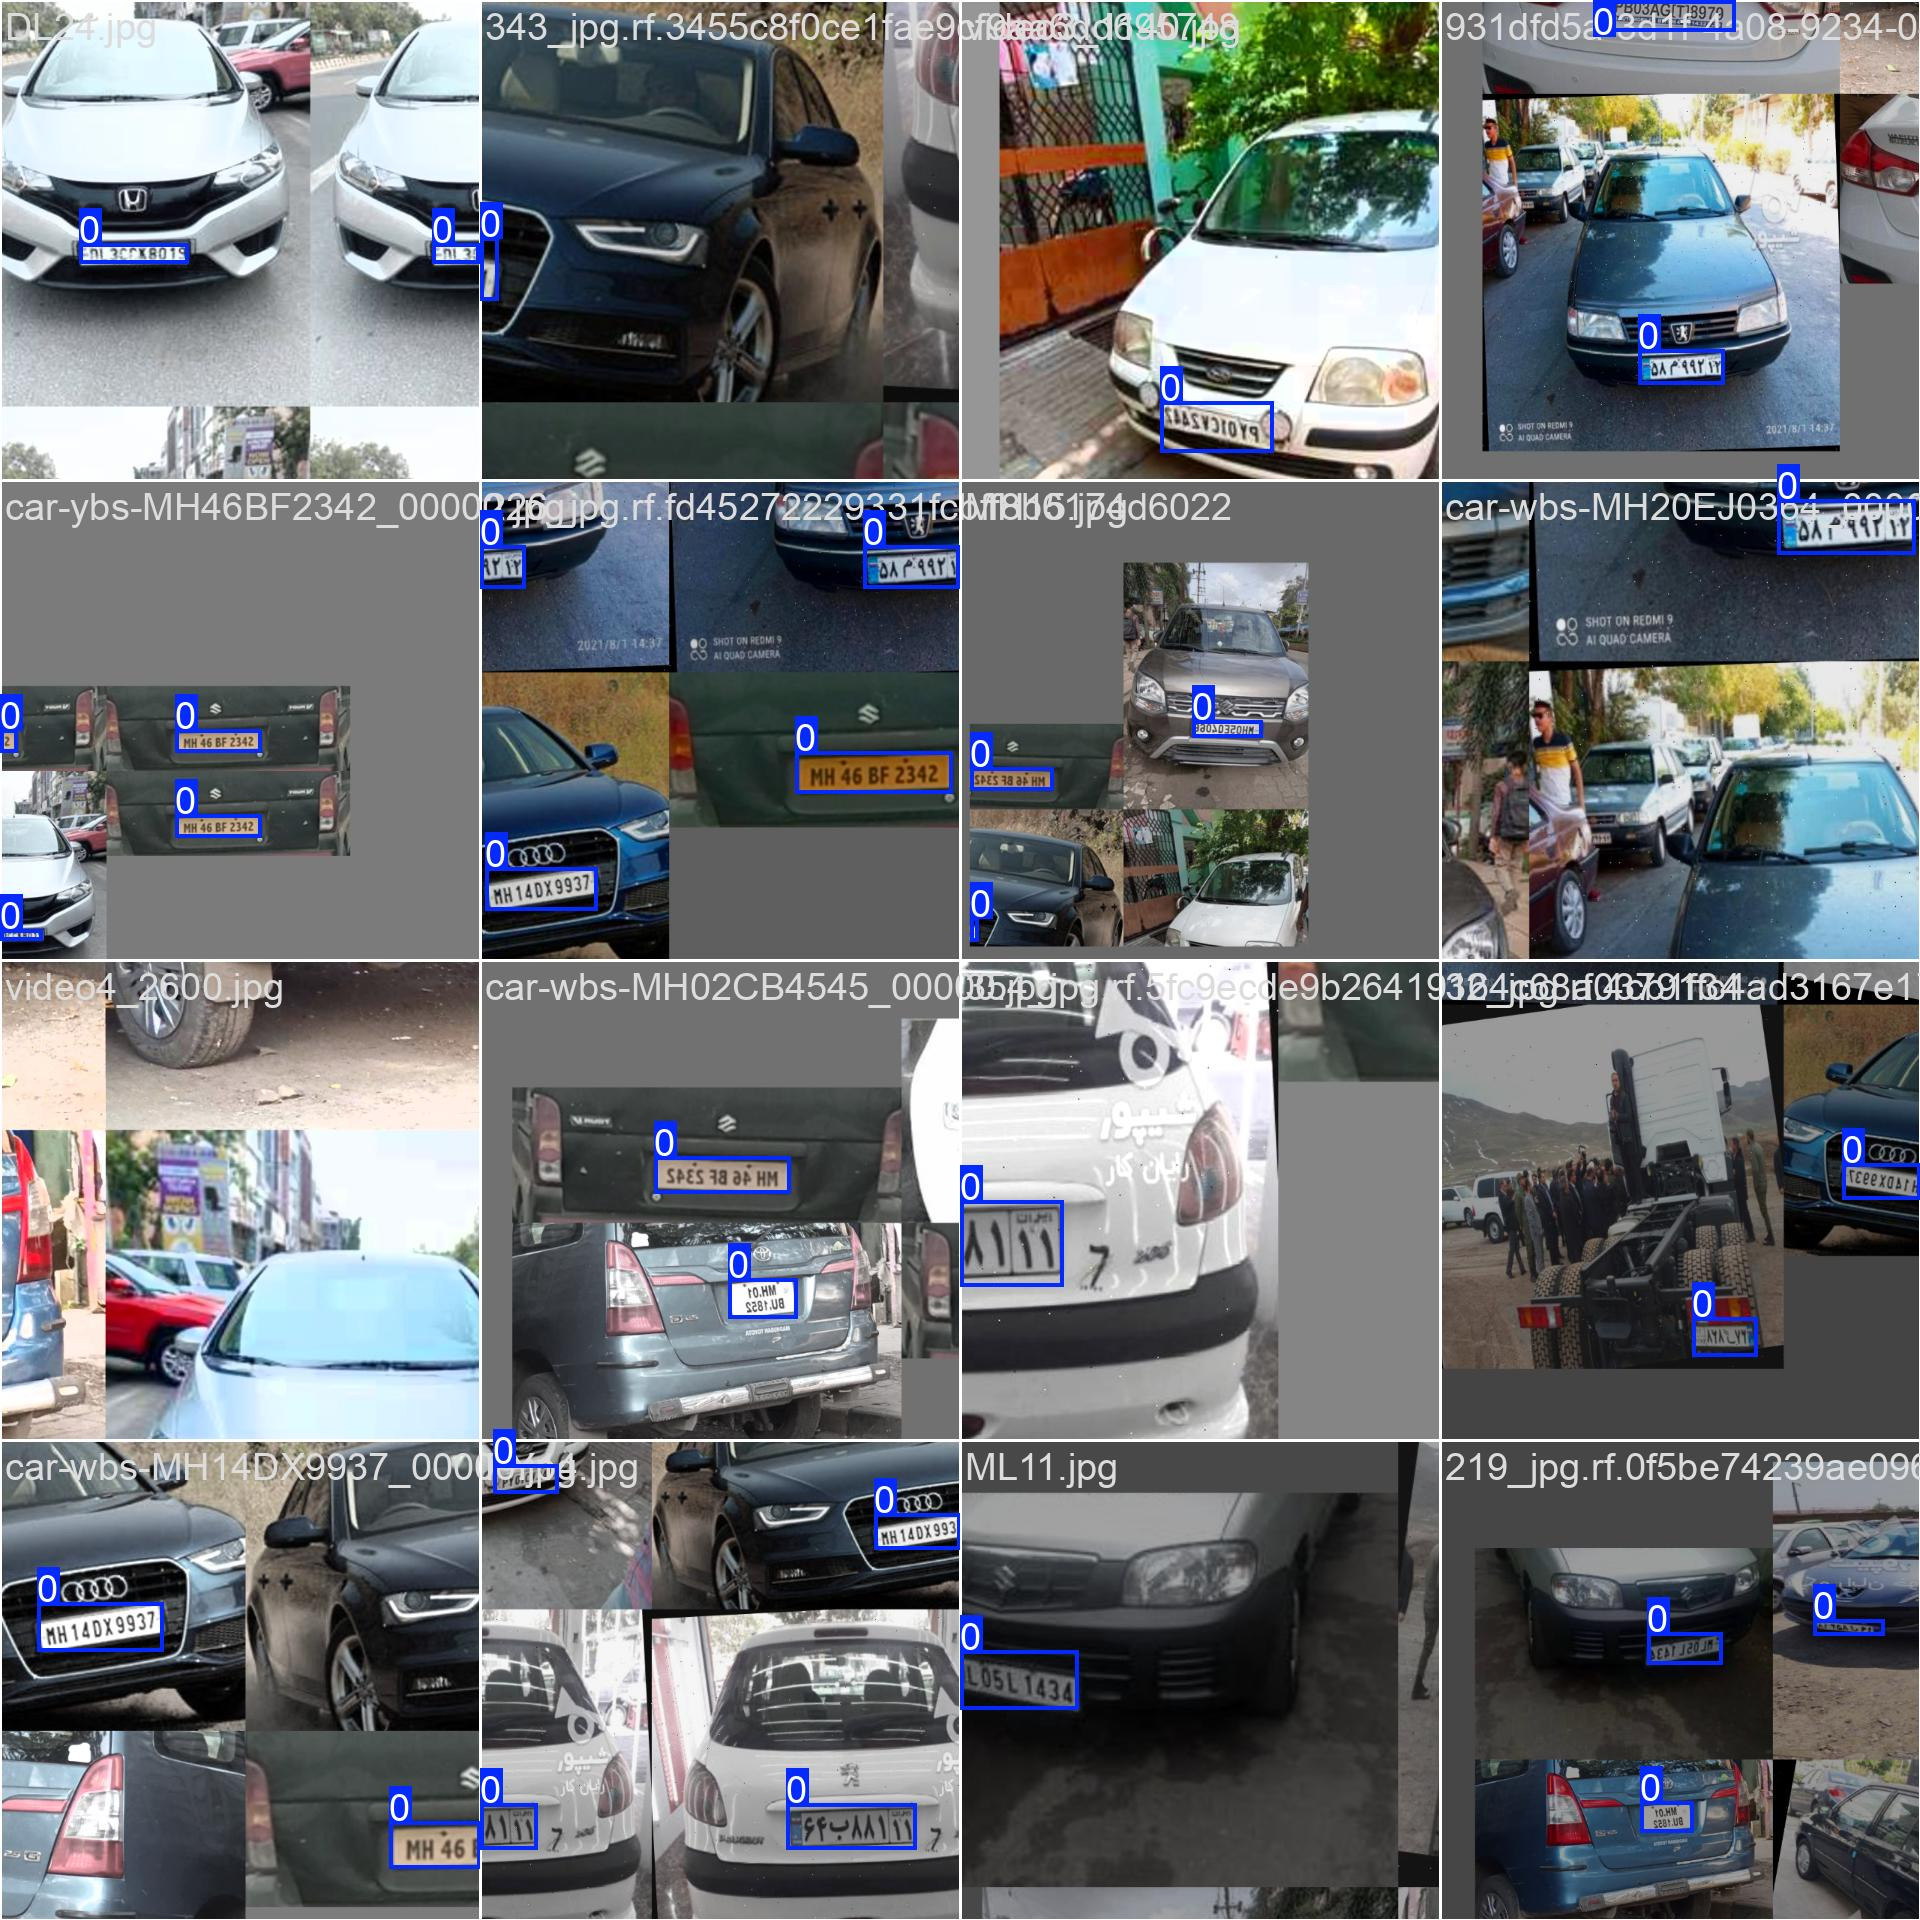

In [24]:
# let's look at the dataset
display(Image(f"{result_path}/train_batch1.jpg", width=600, height=600))

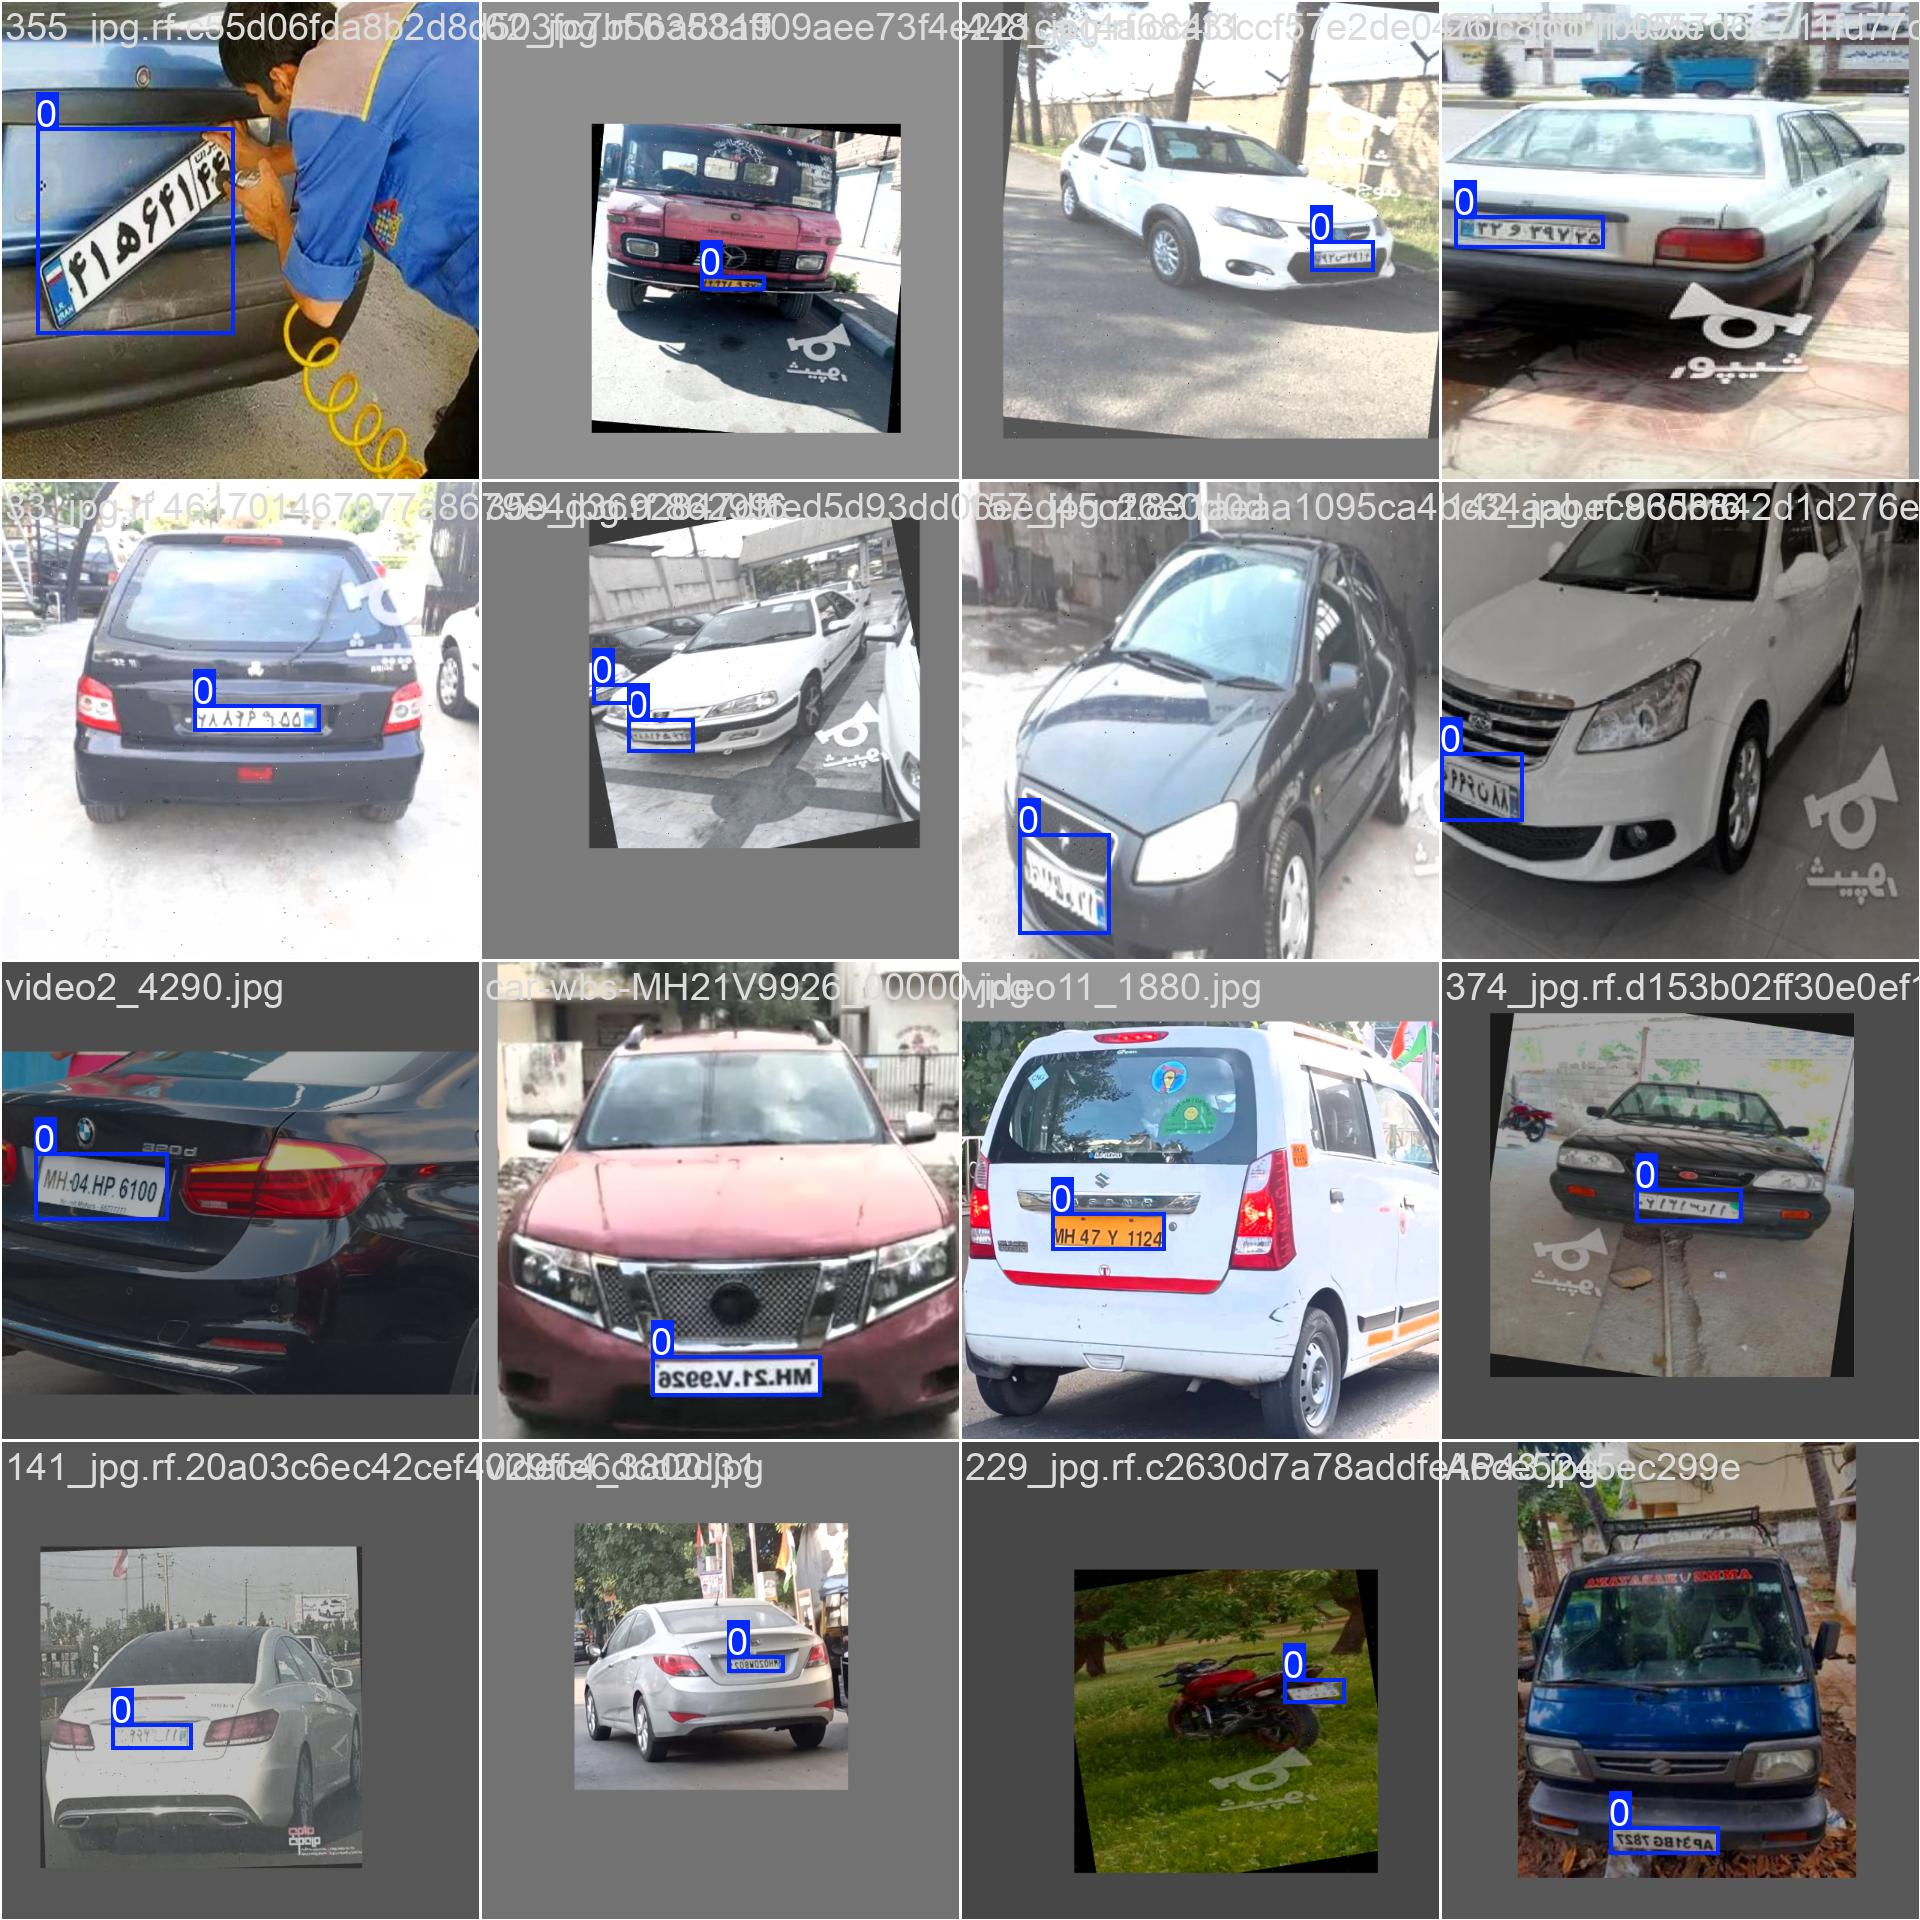

In [25]:
# let's look at the dataset
display(Image(f"{result_path}/train_batch1690.jpg", width=600, height=600))

# Step 3.2 | How well does the model work on val dataset?

### Let's check if the boxes are correctly on class object(license plate).

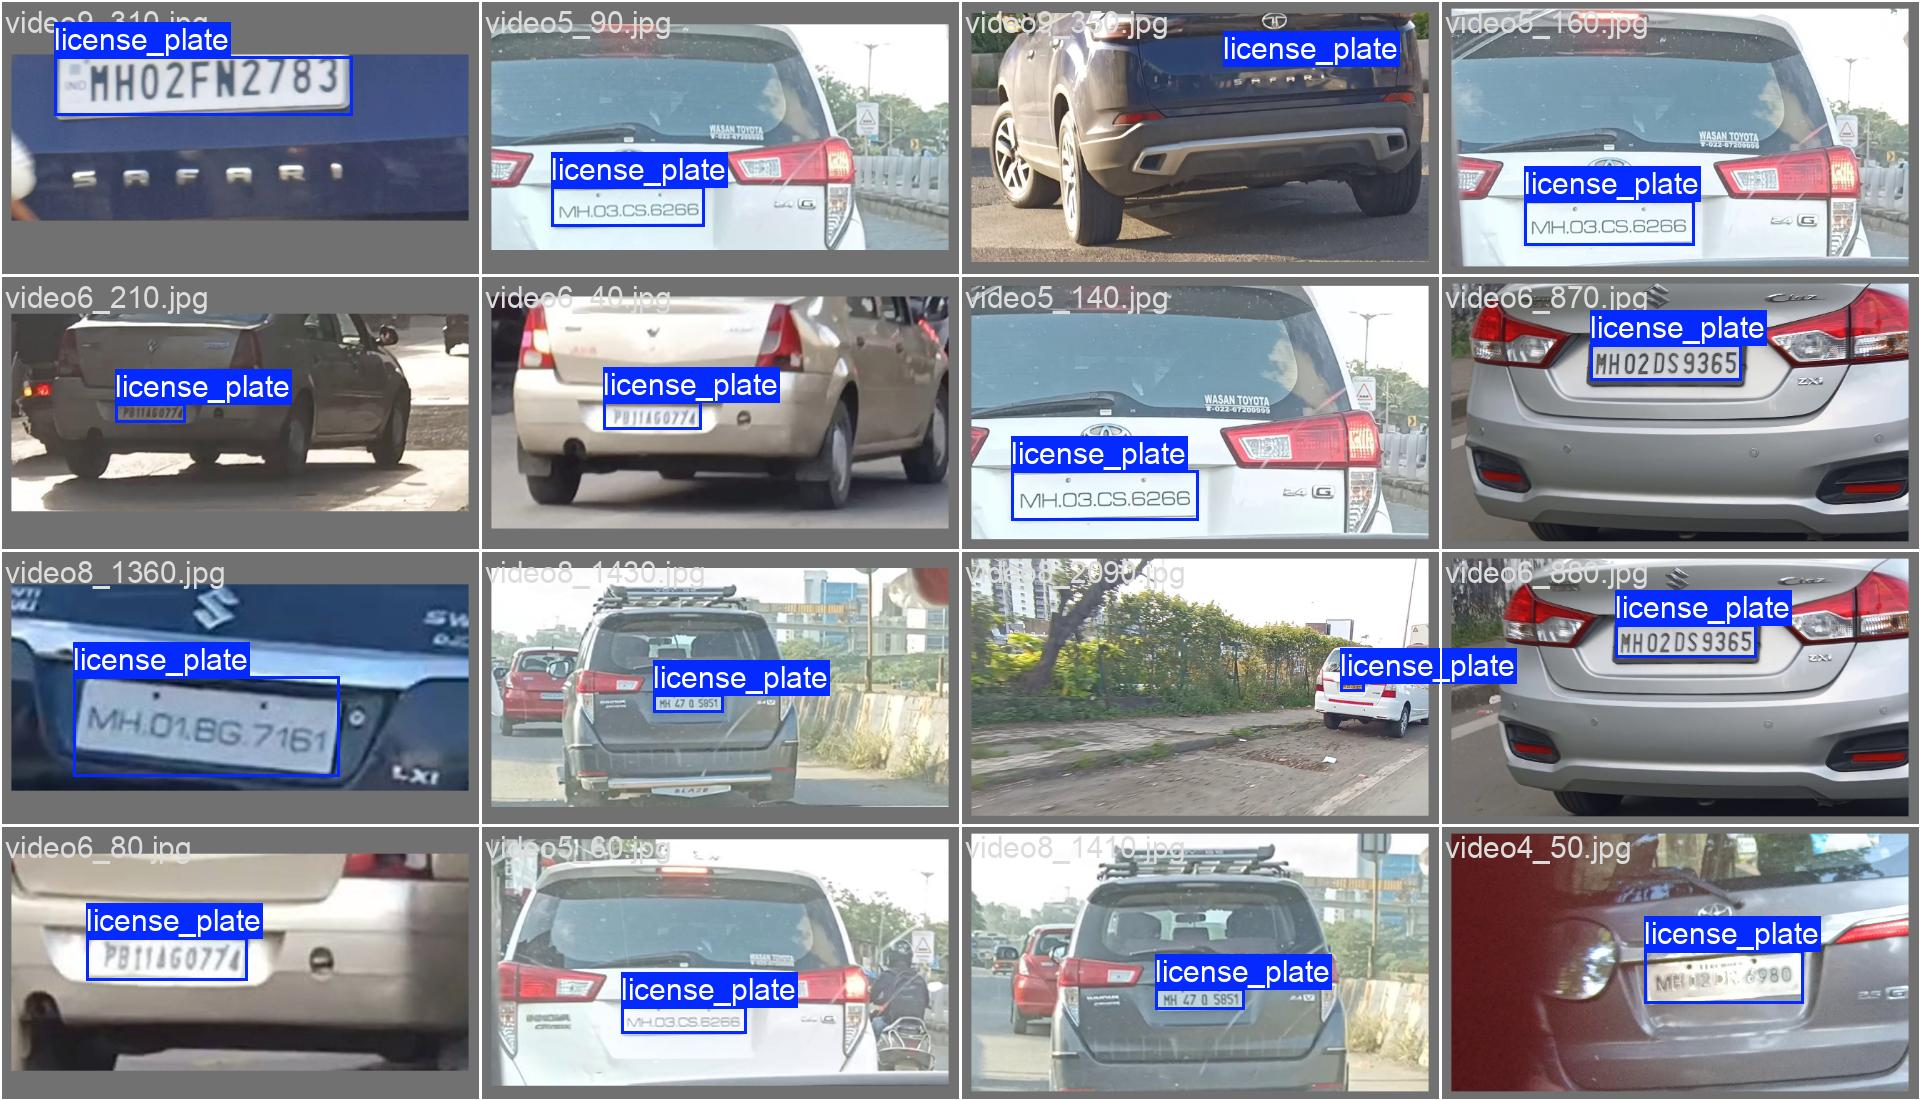

In [19]:
# this is the dataset annotation
display(Image(f"{result_path}/val_batch0_labels.jpg", width=600, height=600))

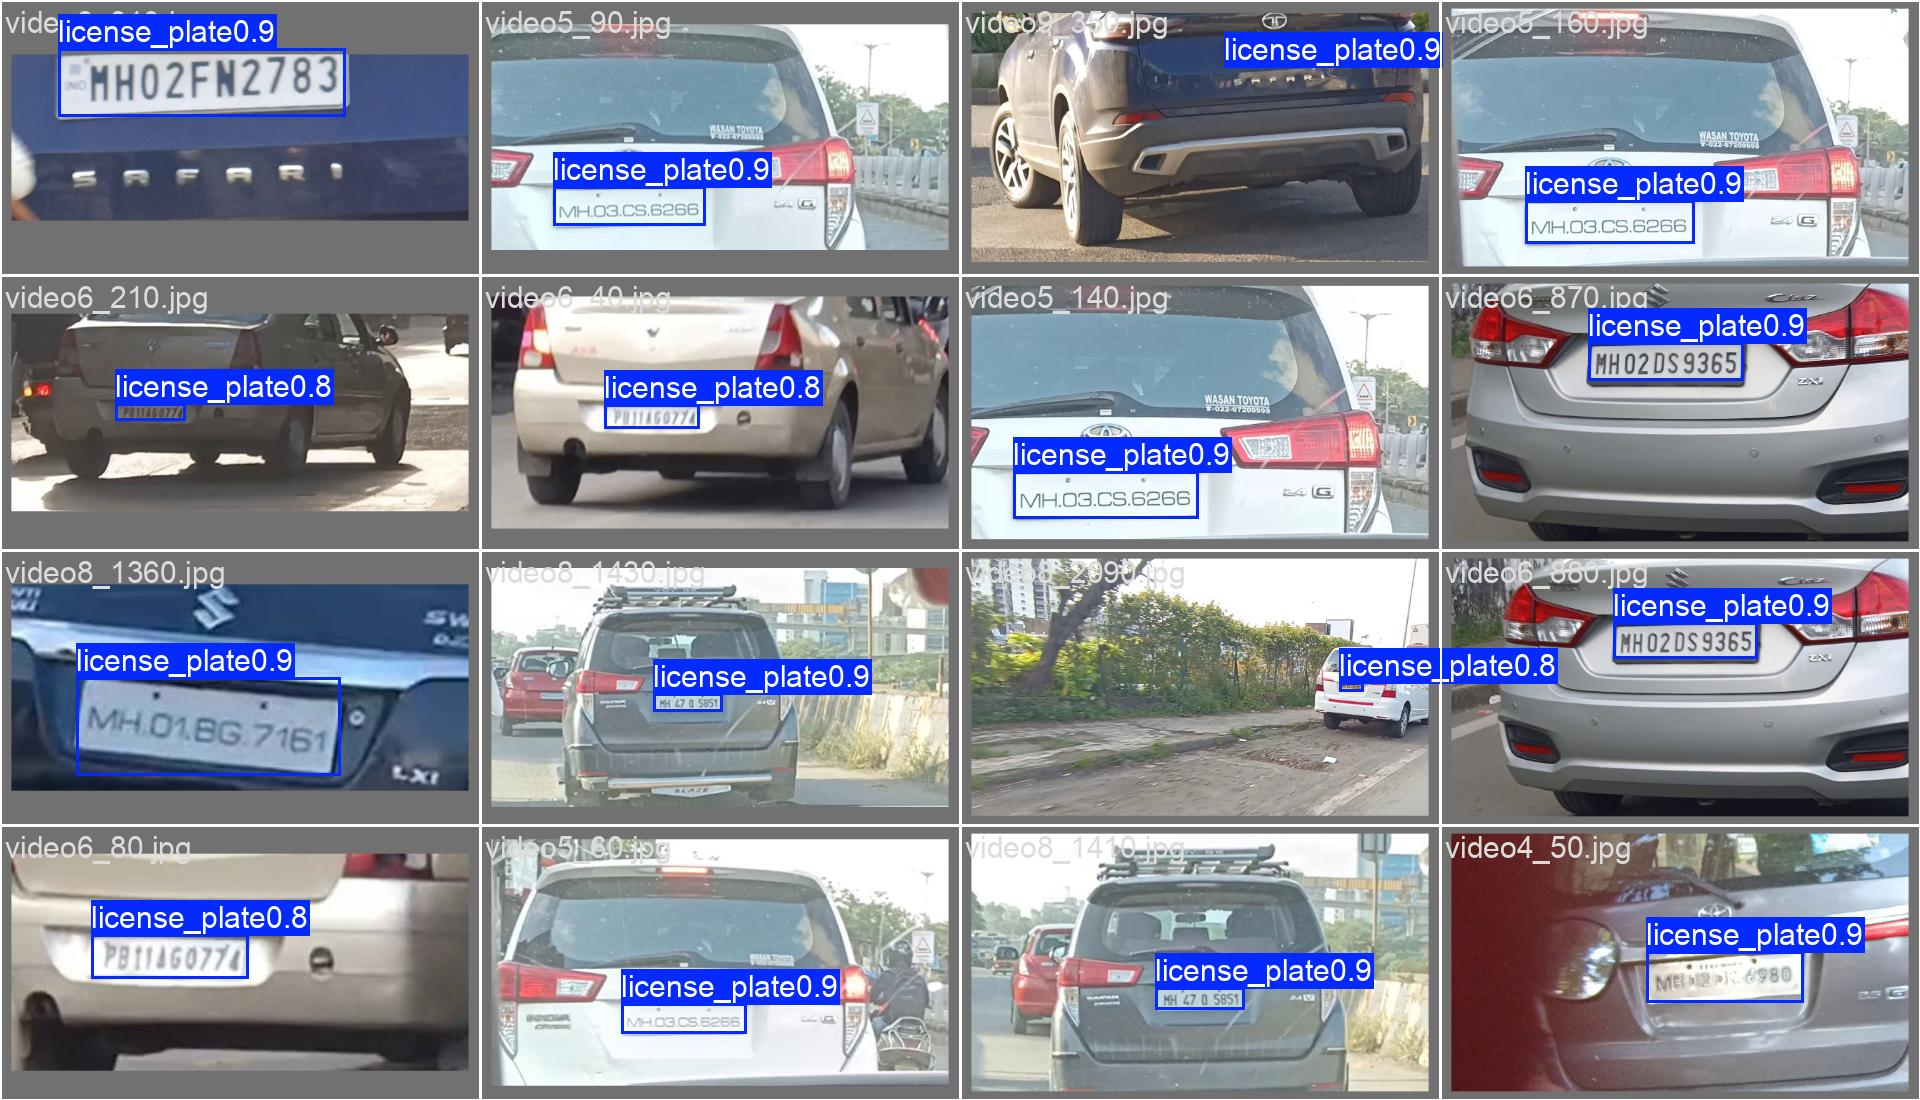

In [20]:
# this is what our model predicted
display(Image(f"{result_path}/val_batch0_pred.jpg", width=600, height=600))

### validation results: 

So here we can see that the model detected plates correctly and with a high accuracy on validation dataset and the bboxes are not too big or too small

### RESULTS:  It works good on val dataset and detects the plates very well.

In [27]:
info = pd.DataFrame([
    ["Training", "Epochs", 20],
    ["Training", "Image Size", 640],

    ["Validation", "Images", 212],
    ["Validation", "Instances", 215],

    ["Final", "Precision", 0.991],
    ["Final", "Recall", 0.981],
    ["Final", "mAP50", 0.991],
    ["Final", "mAP50-95", 0.823],

    ["Best", "Metric", "mAP50-95"],
    ["Best", "Epoch", 20],
    ["Best", "Value", 0.823],
], columns=["Section", "Metric", "Value"])

display(info)

,Section,Metric,Value
0,Training,Epochs,20
1,Training,Image Size,640
2,Validation,Images,212
3,Validation,Instances,215
4,Final,Precision,0.991
5,Final,Recall,0.981
6,Final,mAP50,0.991
7,Final,mAP50-95,0.823
8,Best,Metric,mAP50-95
9,Best,Epoch,20


# Step 4 | Testing the fine-tuned model

In [26]:
# saving the best weights
best_model = YOLO("/kaggle/working/runs/detect/train/weights/best.pt")

In [29]:
test_images_path = "/kaggle/input/datasets/sadafpj/different-images-of-license-plates"


image 1/1 /kaggle/input/datasets/sadafpj/different-images-of-license-plates/car1.jpg: 640x640 1 license_plate, 10.9ms
Speed: 1.2ms preprocess, 10.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


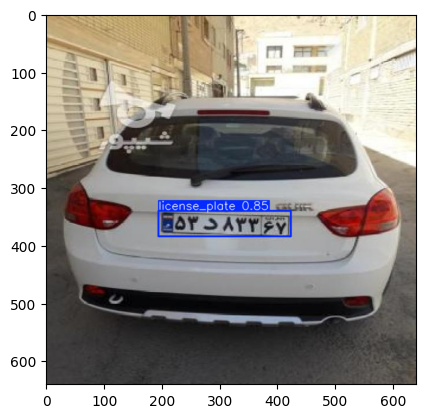

In [37]:
test_results1 = best_model.predict(f"{test_images_path}/car1.jpg")

test_results1 = test_results1[0]

plt.imshow(test_results1.plot()[:, :, ::-1])

In [47]:
x1, y1, x2, y2 = test_results1.boxes.xyxy[0].tolist()

img = cv2.imread(f"{test_images_path}/car1.jpg")

plate = img[int(y1):int(y2), int(x1):int(x2)]

cv2.imwrite("car1_plate.jpg", plate)

True


image 1/1 /kaggle/input/datasets/sadafpj/different-images-of-license-plates/car2.jpg: 640x640 1 license_plate, 12.2ms
Speed: 1.1ms preprocess, 12.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


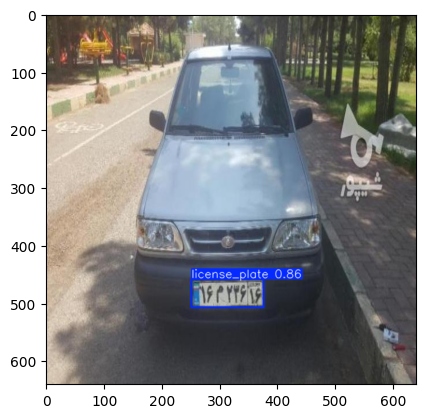

In [38]:
test_results2 = best_model.predict(f"{test_images_path}/car2.jpg")

test_results2 = test_results2[0]

plt.imshow(test_results2.plot()[:, :, ::-1])

In [48]:
x1, y1, x2, y2 = test_results2.boxes.xyxy[0].tolist()

img = cv2.imread(f"{test_images_path}/car2.jpg")

plate = img[int(y1):int(y2), int(x1):int(x2)]

cv2.imwrite("car2_plate.jpg", plate)

True


image 1/1 /kaggle/input/datasets/sadafpj/different-images-of-license-plates/truck1.jpg: 640x640 1 license_plate, 10.8ms
Speed: 1.1ms preprocess, 10.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


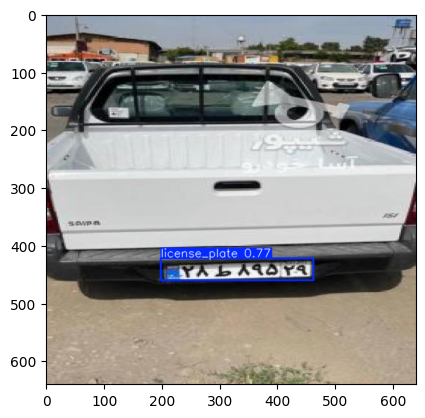

In [44]:
test_results8 = best_model.predict(f"{test_images_path}/truck1.jpg")

test_results8 = test_results8[0]

plt.imshow(test_results8.plot()[:, :, ::-1])

In [58]:
x1, y1, x2, y2 = test_results8.boxes.xyxy[0].tolist()

img = cv2.imread(f"{test_images_path}/truck1.jpg")

plate = img[int(y1):int(y2), int(x1):int(x2)]

cv2.imwrite("truck1.jpg", plate)

True


image 1/1 /kaggle/input/datasets/sadafpj/different-images-of-license-plates/truck2.jpg: 640x640 1 license_plate, 8.6ms
Speed: 1.1ms preprocess, 8.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


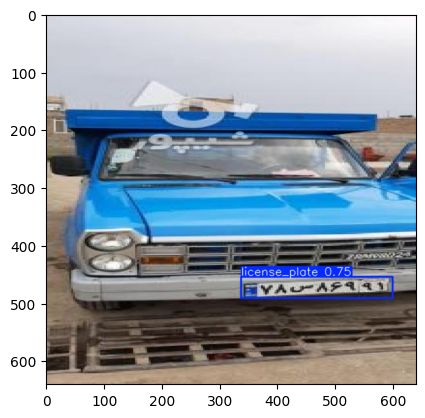

In [45]:
test_results9 = best_model.predict(f"{test_images_path}/truck2.jpg")

test_results9 = test_results9[0]

plt.imshow(test_results9.plot()[:, :, ::-1])

In [59]:
x1, y1, x2, y2 = test_results9.boxes.xyxy[0].tolist()

img = cv2.imread(f"{test_images_path}/truck2.jpg")

plate = img[int(y1):int(y2), int(x1):int(x2)]

cv2.imwrite("truck2.jpg", plate)

True

### So it worked well on test images too. Now I can use this model for my License plate detection project.